# 02 — Experiments and statistical analysis

Results of the experiment designs in `experiments/designs.py` (ODD section 8),
produced by `python -m experiments.run_experiments`. Each scenario runs with the
**same 30 seeds**, so for a given seed every scenario has the same households,
weather and outages (common random numbers). Results are reported as mean ± 95%
confidence interval; scenarios are compared with one-way ANOVA, Kruskal–Wallis
(robust to non-normality and unequal variances) and Tukey HSD, plus paired tests
on the seed-matched differences where two scenarios are compared directly.

Behaviour that responds to prices:
- **Membership change** (E1, E1b): every 30 days a member leaves (probability
  0.5) if it saved less than a threshold over the last 30 days; a non-member
  joins (probability 0.2) if members of its own type (prosumer/consumer) saved
  more than the threshold. 20% of households start outside the community.
  The threshold stands for the cost of taking part (fees, effort): 2 EUR per
  30 days in E1, varied in E1b.
- **Demand response** (E3): flexible households move evening load to the hours
  with the lowest forecast price (smoothed prices of past days).

Tariffs are still placeholders (import 0.20, export 0.05 EUR/kWh), so euro
values are indicative; relative comparisons are what matter at this stage.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
from experiments.stats import compare, paired, replication_check, summary
from model.model import Community

RESULTS = Path("../experiments/results")
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)
pd.set_option("display.width", 200, "display.max_colwidth", 60)

e1, e1b, e2, e3, e4, e5 = (pd.read_csv(RESULTS / f"{n}.csv") for n in
    ["e1_pricing", "e1b_membership_threshold", "e2_storage", "e3_demand_response", "e4_resilience", "e5_sensitivity"])

In [2]:
# Chart style (same as 01_data_check). Fixed colour and marker per entity.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, RED, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#e34948", "#898781"
INK, INK2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": GRAY, "ytick.color": GRAY, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.labelcolor": INK2,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 1.6,
})

MECHS = ["fixed", "mid_market", "sdr", "dynamic", "bill_sharing"]
MECH = {  # label, colour, marker
    "fixed": ("fixed (0.10)", BLUE, "o"),
    "mid_market": ("mid-market", ORANGE, "s"),
    "sdr": ("SDR (Liu)", AQUA, "^"),
    "dynamic": ("dynamic", YELLOW, "D"),
    "bill_sharing": ("bill-sharing", MAGENTA, "v"),
}

def dots(ax, x, s, kpi, labels, color, label, offset=0.0, scale=1.0, line=False, marker="o"):
    """Mean ± 95% CI for the given scenario labels."""
    m = s.loc[labels, (kpi, "mean")].astype(float) * scale
    h = s.loc[labels, (kpi, "ci95")].astype(float) * scale
    ax.errorbar(np.asarray(x) + offset, m, yerr=h, fmt=marker + ("-" if line else ""), color=color, label=label,
                ms=6, capsize=3, elinewidth=1.4, lw=1.6)

def mech_lines(ax, x, s, kpi, label_fn, scale=1.0):
    for m in MECHS:
        name, c, mk = MECH[m]
        dots(ax, x, s, kpi, [label_fn(m, v) for v in x], c, name, scale=scale, line=True, marker=mk)

## Replication check

Is n = 30 enough? Largest relative 95% CI half-width (half-width / mean) of
each KPI over every scenario of every experiment.

In [3]:
everything = pd.concat([e1, e1b, e2, e3, e4, e5])
replication_check(everything, ["community_savings_eur", "self_sufficiency", "self_consumption",
                               "peak_import_kw", "gini_savings", "served_during_outages", "member_share_mean"]).round(3)

,max_rel_halfwidth,worst_scenario
community_savings_eur,0.186563,bill_sharing | pv 20%
self_sufficiency,0.04554,bill_sharing | pv 20%
self_consumption,0.051454,bill_sharing | pv 20%
peak_import_kw,0.023348,sdr | flex 0.2
gini_savings,0.062068,dynamic | threshold 5
served_during_outages,0.26245,bill_sharing | pv 20%
member_share_mean,0.142593,bill_sharing | pv 20%


With 30 seeds the energy KPIs are estimated within a few percent of their mean.
Two KPIs are noisier: the **share of demand served during outages** (outages
cover only ~19 h per year) and savings in the scenarios where the community
**collapses** (bill-sharing, high thresholds), where a run's result depends on
when members happen to leave. For RQ4 either use more seeds or rely on the
outage-heavy regimes of E4.

## E1 — Pricing mechanism × PV share, with membership change (RQ1)

In [4]:
shares = [0.2, 0.4, 0.6, 0.8]
pv_pct = [int(s * 100) for s in shares]
lab = lambda m, pct: f"{m} | pv {pct}%"
s1 = summary(e1, ["community_savings_eur", "self_sufficiency", "gini_savings", "member_share_mean",
                  "prosumer_members_final", "prosumer_savings_eur", "consumer_savings_eur"])
s1.round(3)

community_savings_eur          self_sufficiency        gini_savings        member_share_mean        prosumer_members_final        prosumer_savings_eur          \
                                       mean     ci95             mean   ci95         mean   ci95              mean   ci95                   mean   ci95                 mean    ci95   
scenario                                                                                                                                                                               
none | pv 20%                        -0.000    0.000            0.083  0.002        0.000  0.000             0.800  0.000                  4.867  0.376               -0.000   0.000   
fixed | pv 20%                     2884.381  123.602            0.256  0.007        0.238  0.009             0.927  0.012                  5.967  0.068              160.996   6.900   
mid_market | pv 20%                2874.046  127.187            0.255  0.007        0.386  0.007             0.920  0.015                  5.967  0.068              240.392  10.641   
sdr | pv 20%                       2709.105  134.601            0.245  0.008        0.242  0.014             0.894  0.016                  5.067  0.293               42.098   2.307   
dynamic | pv 20%                   2852.027  134.619            0.254  0.008        0.416  0.013             0.893  0.022                  5.967  0.068              249.346  10.653   
bill_sharing | pv 20%               426.636   79.594            0.109  0.005        0.825  0.014             0.344  0.049                  0.000  0.000              -23.676   4.416   
none | pv 40%                        -0.000    0.000            0.167  0.002        0.000  0.000             0.800  0.000                  9.200  0.409               -0.000   0.000   
fixed | pv 40%                     2845.348   55.433            0.337  0.003        0.199  0.011             0.927  0.009                 11.233  0.335               79.703   1.513   
mid_market | pv 40%                2845.223   56.153            0.337  0.003        0.235  0.012             0.929  0.009                 11.833  0.142              119.223   2.304   
sdr | pv 40%                       2345.379   65.179            0.307  0.004        0.433  0.008             0.735  0.009                  4.800  0.558               12.842   0.578   
dynamic | pv 40%                   2851.888   57.406            0.337  0.003        0.204  0.012             0.928  0.009                 11.433  0.234               88.591   2.703   
bill_sharing | pv 40%               579.763   69.546            0.202  0.004        0.986  0.013             0.341  0.033                  0.000  0.000              -16.045   1.930   
none | pv 60%                         0.000    0.000            0.247  0.002        0.000  0.000             0.800  0.000                 14.267  0.438                0.000   0.000   
fixed | pv 60%                     2101.251   66.652            0.372  0.003        0.375  0.010             0.868  0.011                 13.133  0.526               39.507   1.243   
mid_market | pv 60%                2130.458   58.776            0.373  0.003        0.234  0.011             0.919  0.009                 15.700  0.429               59.826   1.636   
sdr | pv 60%                       1624.223  110.462            0.343  0.007        0.630  0.008             0.527  0.027                  4.067  0.665                4.791   0.354   
dynamic | pv 60%                   2116.010   54.780            0.373  0.003        0.442  0.012             0.812  0.015                 12.433  0.457               31.845   1.360   
bill_sharing | pv 60%               627.659   66.317            0.284  0.005        1.168  0.015             0.299  0.023                  0.000  0.000              -11.499   1.224   
none | pv 80%                        -0.000    0.000            0.331  0.002        0.000  0.000             0.800  0.000                 19.100  0.330       

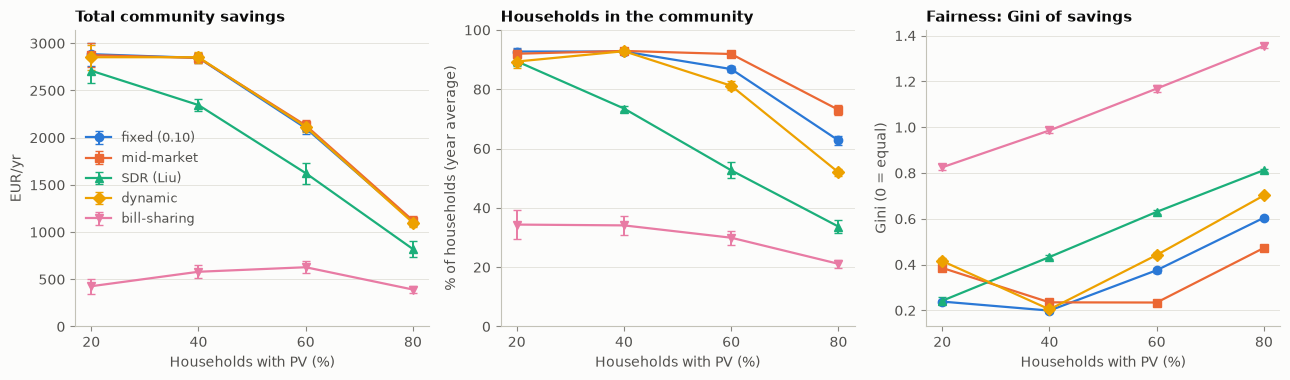

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
mech_lines(axes[0], pv_pct, s1, "community_savings_eur", lab)
axes[0].set_title("Total community savings", loc="left")
axes[0].set_ylabel("EUR/yr")
mech_lines(axes[1], pv_pct, s1, "member_share_mean", lab, scale=100)
axes[1].set_title("Households in the community", loc="left")
axes[1].set_ylabel("% of households (year average)")
mech_lines(axes[2], pv_pct, s1, "gini_savings", lab)
axes[2].set_title("Fairness: Gini of savings", loc="left")
axes[2].set_ylabel("Gini (0 = equal)")
for ax in axes:
    ax.set_xticks(pv_pct)
    ax.set_xlabel("Households with PV (%)")
axes[0].set_ylim(bottom=0)
axes[1].set_ylim(0, 100)
axes[0].legend(loc="center left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGS / "e1_pricing.png", dpi=150)

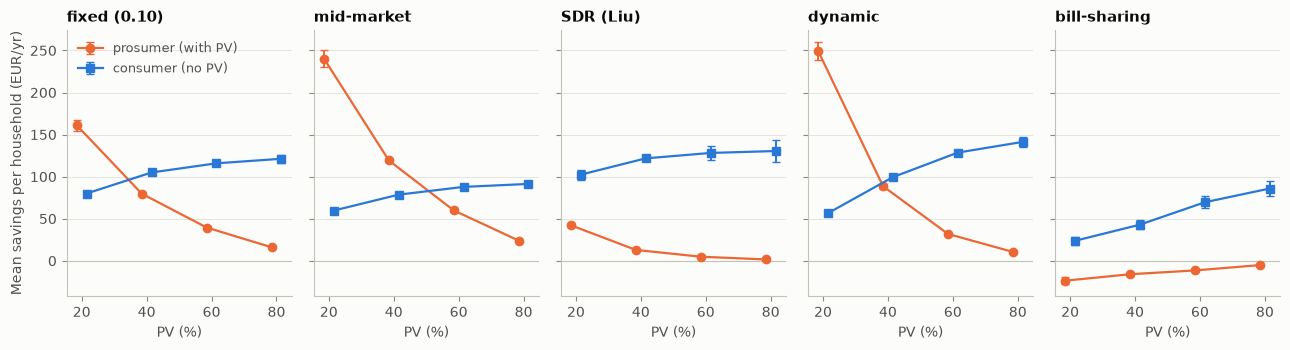

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3.6), sharey=True)
for ax, m in zip(axes, MECHS):
    labels = [lab(m, p) for p in pv_pct]
    dots(ax, pv_pct, s1, "prosumer_savings_eur", labels, ORANGE, "prosumer (with PV)", -1.5, line=True)
    dots(ax, pv_pct, s1, "consumer_savings_eur", labels, BLUE, "consumer (no PV)", 1.5, line=True, marker="s")
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_xticks(pv_pct)
    ax.set_title(MECH[m][0], loc="left")
    ax.set_xlabel("PV (%)")
axes[0].set_ylabel("Mean savings per household (EUR/yr)")
axes[0].legend(loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGS / "e1_savings_by_group.png", dpi=150)

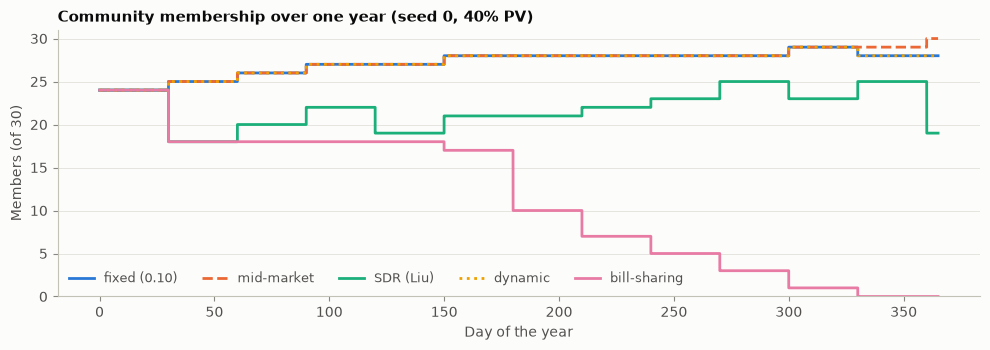

In [7]:
# Membership over the year for one seed (40% PV), to show the dynamics behind the averages
fig, ax = plt.subplots(figsize=(10, 3.6))
styles = {"fixed": "-", "mid_market": "--", "sdr": "-", "dynamic": ":", "bill_sharing": "-"}  # the first three often overlap
for m in MECHS:
    model = Community(pricing=m, membership=True, initial_member_share=0.8, savings_threshold=2.0, rng=0)
    model.run_year()
    n = model.datacollector.get_model_vars_dataframe()["n_members"]
    name, c, mk = MECH[m]
    ax.plot(np.arange(len(n)) / 24, n, color=c, label=name, drawstyle="steps-post", ls=styles[m], lw=2)
ax.set_xlabel("Day of the year")
ax.set_ylabel("Members (of 30)")
ax.set_ylim(0, 31)
ax.set_title("Community membership over one year (seed 0, 40% PV)", loc="left")
ax.legend(loc="lower left", ncol=5, fontsize=9)
fig.tight_layout()
fig.savefig(FIGS / "e1_membership_timeline.png", dpi=150)

In [8]:
# Tests at the baseline PV share (40%), community mechanisms only
e1_40 = e1[(e1["pv_share"] == 0.4) & (e1["pricing"] != "none")]
tests = {}
for kpi in ["community_savings_eur", "member_share_mean", "gini_savings"]:
    tests[kpi] = compare(e1_40, kpi)
pd.concat([t for t, _ in tests.values()]).round(4)

,min_shapiro_p,levene_p,anova_F,anova_p,kruskal_H,kruskal_p
kpi,,,,,,
community_savings_eur,0.1089,0.9760,1084.8080,0.0,112.4664,0.0
member_share_mean,0.0234,0.0000,961.7400,0.0,114.5121,0.0
gini_savings,0.0336,0.0562,3651.2558,0.0,121.0179,0.0


In [9]:
tests["community_savings_eur"][1].round(4)

,a,b,mean_diff,ci_low,ci_high,p_tukey
0,fixed | pv 40%,mid_market | pv 40%,0.1250,-116.3969,116.6469,1.0000
1,fixed | pv 40%,sdr | pv 40%,499.9683,383.4464,616.4902,0.0000
2,fixed | pv 40%,dynamic | pv 40%,-6.5401,-123.0620,109.9817,0.9999
3,fixed | pv 40%,bill_sharing | pv 40%,2265.5845,2149.0626,2382.1064,0.0000
4,mid_market | pv 40%,sdr | pv 40%,499.8433,383.3214,616.3652,0.0000
5,mid_market | pv 40%,dynamic | pv 40%,-6.6651,-123.1870,109.8568,0.9999
6,mid_market | pv 40%,bill_sharing | pv 40%,2265.4595,2148.9377,2381.9814,0.0000
7,sdr | pv 40%,dynamic | pv 40%,-506.5084,-623.0303,-389.9865,0.0000
8,sdr | pv 40%,bill_sharing | pv 40%,1765.6162,1649.0944,1882.1381,0.0000
9,dynamic | pv 40%,bill_sharing | pv 40%,2272.1247,2155.6028,2388.6465,0.0000


In [10]:
pd.DataFrame([paired(e1, "community_savings_eur", lab("dynamic", p), lab("mid_market", p)) for p in pv_pct]
             + [paired(e1, "gini_savings", lab("dynamic", p), lab("mid_market", p)) for p in pv_pct]).round(4)

,a,b,kpi,mean_diff,ci_low,ci_high,p_paired_t,p_wilcoxon
0,dynamic | pv 20%,mid_market | pv 20%,community_savings_eur,-22.0188,-51.4112,7.3736,0.1363,0.0001
1,dynamic | pv 40%,mid_market | pv 40%,community_savings_eur,6.6651,-11.5506,24.8809,0.4603,0.0798
2,dynamic | pv 60%,mid_market | pv 60%,community_savings_eur,-14.4476,-47.6923,18.7971,0.3814,0.3387
3,dynamic | pv 80%,mid_market | pv 80%,community_savings_eur,-23.3201,-55.8421,9.2020,0.1533,0.0879
4,dynamic | pv 20%,mid_market | pv 20%,gini_savings,0.0301,0.0196,0.0405,0.0000,0.0000
5,dynamic | pv 40%,mid_market | pv 40%,gini_savings,-0.0307,-0.0374,-0.0240,0.0000,0.0000
6,dynamic | pv 60%,mid_market | pv 60%,gini_savings,0.2076,0.1966,0.2186,0.0000,0.0000
7,dynamic | pv 80%,mid_market | pv 80%,gini_savings,0.2292,0.2171,0.2412,0.0000,0.0000


**Findings (E1)**

- **The pricing mechanism now changes total savings**, because households
  leave when the community does not pay off (ANOVA and Kruskal–Wallis
  p < 0.001 at 40% PV). Bill-sharing makes prosumers worse off than alone, so
  they leave and the community collapses (~34% of households on average,
  ~80% less savings). Under SDR prosumers earn almost nothing, many leave and
  total savings drop by ~18%.
- **Fixed, mid-market and dynamic keep the community together** and give
  practically the same total savings (differences below 1%; at 40% PV Tukey
  p ≈ 1 and paired dynamic vs mid-market p = 0.46). They differ in how the
  savings are split. At 20% PV the fixed price is the fairest; at 40% fixed
  and dynamic are fairest (Gini ~0.20 vs ~0.24 for mid-market). At 60–80% PV,
  when supply exceeds demand most of the time, the dynamic price falls
  towards p_exp, prosumers leave, and mid-market is both the fairest and the
  best at keeping members.
- **Total savings peak at 20–40% PV** and fall at 60–80%: with many prosumers
  there are too few consumers to absorb the midday surplus.

## E1b — Sensitivity to the participation threshold (40% PV)

community_savings_eur          member_share_mean        gini_savings       
                                            mean     ci95              mean   ci95         mean   ci95
scenario                                                                                              
none | threshold 0                        -0.000    0.000             0.800  0.000        0.000  0.000
fixed | threshold 0                     2845.239   56.156             0.929  0.009        0.199  0.011
mid_market | threshold 0                2845.239   56.156             0.929  0.009        0.235  0.012
sdr | threshold 0                       2845.239   56.156             0.929  0.009        0.459  0.008
dynamic | threshold 0                   2845.239   56.156             0.929  0.009        0.205  0.012
bill_sharing | threshold 0               881.927   85.777             0.531  0.027        0.979  0.016
none | threshold 2                        -0.000    0.000             0.800  0.000        0.000  0.000
fixed | threshold 2                     2845.348   55.433             0.927  0.009        0.199  0.011
mid_market | threshold 2                2845.223   56.153             0.929  0.009        0.235  0.012
sdr | threshold 2                       2345.379   65.179             0.735  0.009        0.433  0.008
dynamic | threshold 2                   2851.888   57.406             0.928  0.009        0.204  0.012
bill_sharing | threshold 2               579.763   69.546             0.341  0.033        0.986  0.013
none | threshold 5                        -0.000    0.000             0.800  0.000        0.000  0.000
fixed | threshold 5                     2760.721   62.336             0.844  0.011        0.241  0.012
mid_market | threshold 5                2615.675   80.913             0.830  0.017        0.281  0.016
sdr | threshold 5                       1520.464  121.155             0.538  0.033        0.474  0.015
dynamic | threshold 5                   2697.358   77.443             0.830  0.015        0.256  0.016
bill_sharing | threshold 5               572.786   74.474             0.305  0.029        0.991  0.014

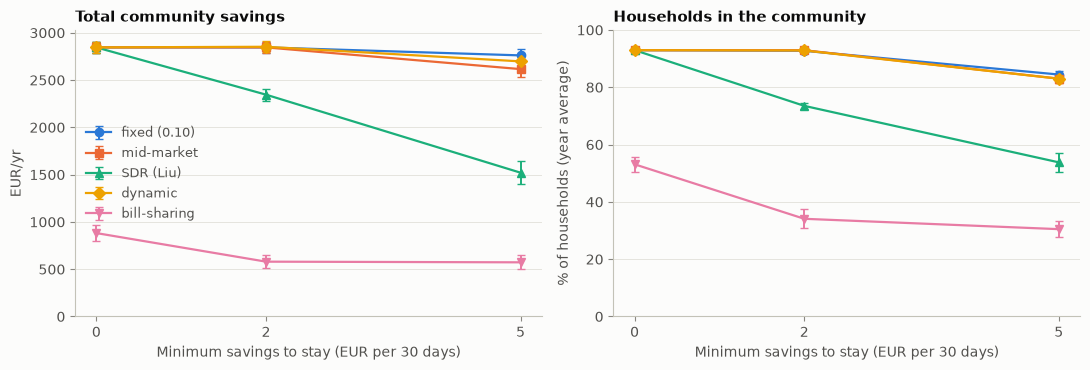

In [11]:
thr = [0, 2, 5]
labb = lambda m, t: f"{m} | threshold {t}"
s1b = summary(e1b, ["community_savings_eur", "member_share_mean", "gini_savings"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
mech_lines(axes[0], thr, s1b, "community_savings_eur", labb)
axes[0].set_title("Total community savings", loc="left")
axes[0].set_ylabel("EUR/yr")
axes[0].set_ylim(bottom=0)
mech_lines(axes[1], thr, s1b, "member_share_mean", labb, scale=100)
axes[1].set_title("Households in the community", loc="left")
axes[1].set_ylabel("% of households (year average)")
axes[1].set_ylim(0, 100)
for ax in axes:
    ax.set_xticks(thr)
    ax.set_xlabel("Minimum savings to stay (EUR per 30 days)")
axes[0].legend(loc="center left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGS / "e1b_threshold.png", dpi=150)
s1b.round(3)

**Findings (E1b)**

- With a **0 EUR threshold** only bill-sharing loses members: every other
  mechanism prices local energy between p_exp and p_imp, so no household is
  ever worse off than alone, and fixed, mid-market, SDR and dynamic give
  identical totals again.
- The higher the cost of taking part, the more the **mechanisms separate**:
  at 5 EUR per 30 days SDR loses about half its total savings, while fixed,
  dynamic and mid-market lose 3–8%, mostly through prosumers leaving in winter.
- The conclusion "SDR and bill-sharing are not stable" is robust; the size of
  the effect depends on the participation cost, which should be justified
  (e.g. from real Portuguese energy-community fees).

## E2 — Shared vs individual storage (RQ2)

In [12]:
s2 = summary(e2, ["community_savings_eur", "self_sufficiency", "self_consumption", "peak_import_kw",
                  "gini_savings", "prosumer_savings_eur", "consumer_savings_eur"])
s2.round(3)

community_savings_eur          self_sufficiency        self_consumption        peak_import_kw        gini_savings        prosumer_savings_eur         consumer_savings_eur       
                                    mean     ci95             mean   ci95             mean   ci95           mean   ci95         mean   ci95                 mean    ci95                 mean   ci95
scenario                                                                                                                                                                                            
none                            3060.475   46.746            0.350  0.003            0.626  0.012         26.777  0.378        0.201  0.006              128.258   1.905               84.521  1.334
individual 50 kWh               3965.817   48.489            0.409  0.005            0.755  0.012         26.271  0.410        0.426  0.005              250.638   2.335               53.231  1.253
shared 50 kWh                   4898.420   60.211            0.464  0.005            0.852  0.013         26.777  0.378        0.242  0.004              242.617   2.827              120.049  1.734
individual 100 kWh              4489.943   52.967            0.442  0.005            0.823  0.014         25.970  0.420        0.465  0.006              302.692   2.853               47.647  1.488
shared 100 kWh                  5975.937  128.546            0.531  0.011            0.983  0.006         26.736  0.377        0.266  0.004              313.228   7.721              138.412  2.771
individual 200 kWh              4598.481   56.863            0.448  0.005            0.836  0.014         25.517  0.476        0.475  0.006              314.500   3.306               45.804  1.457
shared 200 kWh                  6132.506  175.993            0.541  0.013            1.000  0.000         26.736  0.377        0.268  0.004              322.938  10.773              141.094  3.579

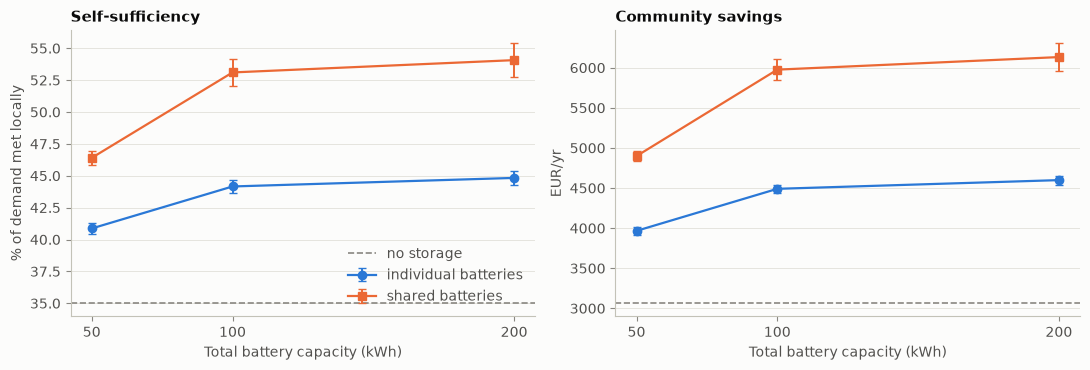

In [13]:
kwh = [50, 100, 200]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, kpi, scale, title, ylabel in [
    (axes[0], "self_sufficiency", 100, "Self-sufficiency", "% of demand met locally"),
    (axes[1], "community_savings_eur", 1, "Community savings", "EUR/yr"),
]:
    for mode, c, mk in [("individual", BLUE, "o"), ("shared", ORANGE, "s")]:
        dots(ax, kwh, s2, kpi, [f"{mode} {k} kWh" for k in kwh], c, f"{mode} batteries", scale=scale, line=True, marker=mk)
    ax.axhline(s2.loc["none", (kpi, "mean")] * scale, color=GRAY, ls="--", lw=1.2, label="no storage")
    ax.set_title(title, loc="left")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Total battery capacity (kWh)")
    ax.set_xticks(kwh)
axes[0].legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGS / "e2_storage.png", dpi=150)

In [14]:
t, _ = compare(e2, "self_sufficiency")
display(t.round(4))
pd.DataFrame([paired(e2, kpi, f"shared {k} kWh", f"individual {k} kWh")
              for kpi in ["community_savings_eur", "self_sufficiency"] for k in kwh]).round(4)

,min_shapiro_p,levene_p,anova_F,anova_p,kruskal_H,kruskal_p
kpi,,,,,,
self_sufficiency,0.0124,0.0,320.856,0.0,185.652,0.0


,a,b,kpi,mean_diff,ci_low,ci_high,p_paired_t,p_wilcoxon
0,shared 50 kWh,individual 50 kWh,community_savings_eur,932.6028,919.1414,946.0643,0.0,0.0
1,shared 100 kWh,individual 100 kWh,community_savings_eur,1485.9933,1398.0393,1573.9473,0.0,0.0
2,shared 200 kWh,individual 200 kWh,community_savings_eur,1534.0248,1401.3858,1666.6637,0.0,0.0
3,shared 50 kWh,individual 50 kWh,self_sufficiency,0.0554,0.0543,0.0564,0.0,0.0
4,shared 100 kWh,individual 100 kWh,self_sufficiency,0.0894,0.0834,0.0955,0.0,0.0
5,shared 200 kWh,individual 200 kWh,self_sufficiency,0.0924,0.0835,0.1012,0.0,0.0


**Findings (E2)**

- **The shared battery beats the same capacity split into home batteries** at
  every size, in both self-sufficiency and savings (paired differences, all
  p < 0.001; about +1,500 EUR/yr and +9 percentage points of self-sufficiency
  at 100 kWh). A shared battery can store any member's surplus and serve any
  member's deficit; a home battery only serves its own house.
- **Diminishing returns**: going from 100 to 200 kWh adds little, because the
  community's daily surplus rarely fills more than ~100 kWh.
- Home batteries concentrate the gain on prosumers (Gini ~0.47); the shared
  battery spreads it (Gini ~0.27).

## E3 — Price-responsive demand response × pricing (RQ3)

community_savings_eur         self_sufficiency        peak_import_kw        gini_savings       
                                       mean    ci95             mean   ci95           mean   ci95         mean   ci95
scenario                                                                                                             
mid_market | flex 0.0              3060.475  46.746            0.350  0.003         26.777  0.378        0.201  0.006
mid_market | flex 0.1              3957.766  52.397            0.403  0.003         25.234  0.403        0.228  0.004
mid_market | flex 0.2              4600.800  60.598            0.442  0.004         32.125  0.615        0.253  0.004
sdr | flex 0.0                     3060.475  46.746            0.350  0.003         26.777  0.378        0.436  0.003
sdr | flex 0.1                     3971.586  52.457            0.404  0.003         25.337  0.413        0.323  0.004
sdr | flex 0.2                     4625.043  61.319            0.443  0.004         34.516  0.806        0.253  0.006
dynamic | flex 0.0                 3060.475  46.746            0.350  0.003         26.777  0.378        0.169  0.007
dynamic | flex 0.1                 3994.208  52.593            0.406  0.003         25.354  0.423        0.169  0.008
dynamic | flex 0.2                 4634.263  62.551            0.444  0.005         33.693  0.764        0.217  0.008

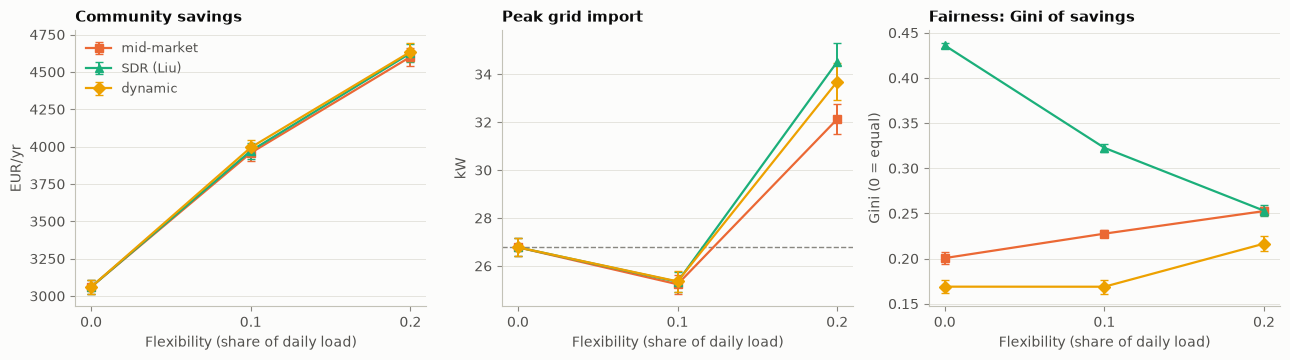

In [15]:
flex = [0.0, 0.1, 0.2]
lab3 = lambda m, f: f"{m} | flex {f}"
s3 = summary(e3, ["community_savings_eur", "self_sufficiency", "peak_import_kw", "gini_savings"])
display(s3.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
for ax, kpi, title, ylabel in [(axes[0], "community_savings_eur", "Community savings", "EUR/yr"),
                               (axes[1], "peak_import_kw", "Peak grid import", "kW"),
                               (axes[2], "gini_savings", "Fairness: Gini of savings", "Gini (0 = equal)")]:
    for m in ["mid_market", "sdr", "dynamic"]:
        name, c, mk = MECH[m]
        dots(ax, flex, s3, kpi, [lab3(m, f) for f in flex], c, name, line=True, marker=mk)
    ax.set_title(title, loc="left")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Flexibility (share of daily load)")
    ax.set_xticks(flex)
axes[1].axhline(s3.loc[lab3("mid_market", 0.0), ("peak_import_kw", "mean")], color=GRAY, ls="--", lw=1.0)
axes[0].legend(loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGS / "e3_demand_response.png", dpi=150)

In [16]:
rows = []
for m in ["mid_market", "sdr", "dynamic"]:
    for f in [0.1, 0.2]:
        for kpi in ["community_savings_eur", "peak_import_kw"]:
            rows.append(paired(e3, kpi, lab3(m, f), lab3(m, 0.0)))
for m in ["sdr", "dynamic"]:
    for kpi in ["community_savings_eur", "peak_import_kw"]:
        rows.append(paired(e3, kpi, lab3(m, 0.2), lab3("mid_market", 0.2)))
pd.DataFrame(rows).round(4)

,a,b,kpi,mean_diff,ci_low,ci_high,p_paired_t,p_wilcoxon
0,mid_market | flex 0.1,mid_market | flex 0.0,community_savings_eur,897.2912,888.5509,906.0315,0.0,0.0
1,mid_market | flex 0.1,mid_market | flex 0.0,peak_import_kw,-1.5426,-1.7295,-1.3558,0.0,0.0
2,mid_market | flex 0.2,mid_market | flex 0.0,community_savings_eur,1540.3249,1518.8302,1561.8196,0.0,0.0
3,mid_market | flex 0.2,mid_market | flex 0.0,peak_import_kw,5.3482,4.9874,5.7091,0.0,0.0
4,sdr | flex 0.1,sdr | flex 0.0,community_savings_eur,911.1112,902.2061,920.0162,0.0,0.0
5,sdr | flex 0.1,sdr | flex 0.0,peak_import_kw,-1.4397,-1.6285,-1.2509,0.0,0.0
6,sdr | flex 0.2,sdr | flex 0.0,community_savings_eur,1564.5684,1541.7287,1587.4081,0.0,0.0
7,sdr | flex 0.2,sdr | flex 0.0,peak_import_kw,7.7396,7.1671,8.3120,0.0,0.0
8,dynamic | flex 0.1,dynamic | flex 0.0,community_savings_eur,933.7332,924.6483,942.8181,0.0,0.0
9,dynamic | flex 0.1,dynamic | flex 0.0,peak_import_kw,-1.4228,-1.6138,-1.2317,0.0,0.0


**Findings (E3)**

- Demand response **adds savings on top of sharing**: about +900 EUR/yr at
  flexibility 0.1 and +1,550 EUR/yr at 0.2 (paired p < 0.001 for every
  mechanism).
- Because households now move load to the hours with the lowest *forecast
  price* and spread it in proportion to the expected saving, flexibility 0.1
  **lowers** the peak grid import (~25 kW vs ~27 kW). At 0.2 the peak rises
  again (~32–35 kW, against ~42 kW with the earlier PV-forecast rule): when
  much load moves on a cloudy day after a sunny one, it is imported.
- With demand response the mechanisms differ slightly in total savings
  (SDR and dynamic +24 to +33 EUR/yr vs mid-market, p < 0.001) because their
  stronger price signals move more load into surplus hours, at the cost of a
  slightly higher peak.

## E4 — Resilience to outages (RQ4)

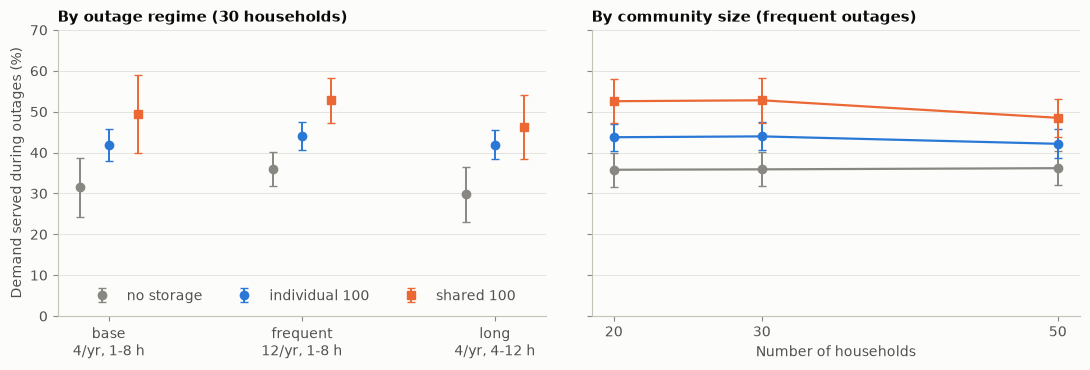

In [17]:
s4 = summary(e4, ["served_during_outages", "lost_load_kwh", "lost_load_alone_kwh", "outage_hours"])
regimes = ["base (4/yr, 1-8 h)", "frequent (12/yr, 1-8 h)", "long (4/yr, 4-12 h)"]
storage_opts = [("no storage", GRAY, "o"), ("individual 100", BLUE, "o"), ("shared 100", ORANGE, "s")]
lab4 = lambda r, s, n: f"{r} | {s} | n={n}"

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
x = np.arange(len(regimes))
for (st, c, mk), off in zip(storage_opts, [-0.15, 0, 0.15]):
    dots(axes[0], x, s4, "served_during_outages", [lab4(r, st, 30) for r in regimes], c, st, off, scale=100, marker=mk)
axes[0].set_xticks(x, ["base\n4/yr, 1-8 h", "frequent\n12/yr, 1-8 h", "long\n4/yr, 4-12 h"])
axes[0].set_title("By outage regime (30 households)", loc="left")
axes[0].set_ylabel("Demand served during outages (%)")
axes[0].legend(loc="lower center", ncol=3)
sizes = [20, 30, 50]
for st, c, mk in storage_opts:
    dots(axes[1], sizes, s4, "served_during_outages", [lab4("frequent (12/yr, 1-8 h)", st, n) for n in sizes],
         c, st, scale=100, line=True, marker=mk)
axes[1].set_xticks(sizes)
axes[1].set_xlabel("Number of households")
axes[1].set_title("By community size (frequent outages)", loc="left")
axes[0].set_ylim(0, 70)
fig.tight_layout()
fig.savefig(FIGS / "e4_resilience.png", dpi=150)

In [18]:
pd.concat([compare(e4[e4["scenario"].isin([lab4(r, st, 30) for st, _, _ in storage_opts])], "served_during_outages")[0]
           .rename(index={"served_during_outages": r}) for r in regimes]).round(4)

,min_shapiro_p,levene_p,anova_F,anova_p,kruskal_H,kruskal_p
kpi,,,,,,
"base (4/yr, 1-8 h)",0.5547,0.0004,6.3974,0.0026,10.7430,0.0046
"frequent (12/yr, 1-8 h)",0.5209,0.1414,15.2430,0.0000,22.4605,0.0000
"long (4/yr, 4-12 h)",0.0317,0.0037,7.5824,0.0009,12.9790,0.0015


In [19]:
pd.DataFrame([paired(e4, "served_during_outages", lab4(r, "shared 100", 30), lab4(r, b, 30))
              for r in regimes for b in ["no storage", "individual 100"]]).round(4)

,a,b,kpi,mean_diff,ci_low,ci_high,p_paired_t,p_wilcoxon
0,"base (4/yr, 1-8 h) | shared 100 | n=30","base (4/yr, 1-8 h) | no storage | n=30",served_during_outages,0.1798,0.1150,0.2447,0.0000,0.0000
1,"base (4/yr, 1-8 h) | shared 100 | n=30","base (4/yr, 1-8 h) | individual 100 | n=30",served_during_outages,0.0767,0.0067,0.1468,0.0329,0.0155
2,"frequent (12/yr, 1-8 h) | shared 100 | n=30","frequent (12/yr, 1-8 h) | no storage | n=30",served_during_outages,0.1690,0.1356,0.2023,0.0000,0.0000
3,"frequent (12/yr, 1-8 h) | shared 100 | n=30","frequent (12/yr, 1-8 h) | individual 100 | n=30",served_during_outages,0.0883,0.0590,0.1176,0.0000,0.0000
4,"long (4/yr, 4-12 h) | shared 100 | n=30","long (4/yr, 4-12 h) | no storage | n=30",served_during_outages,0.1640,0.1164,0.2117,0.0000,0.0000
5,"long (4/yr, 4-12 h) | shared 100 | n=30","long (4/yr, 4-12 h) | individual 100 | n=30",served_during_outages,0.0424,-0.0131,0.0979,0.1294,0.0667


**Findings (E4)**

- Even **without storage**, the community serves ~30–36% of demand during
  outages (midday outages are covered by PV), and its lost load is ~20–25%
  lower than the same households alone, because prosumers' surplus reaches
  their neighbours.
- A **100 kWh shared battery** raises the served share to ~46–53%; individual
  batteries to ~42–44%. Shared beats no storage in every regime (paired
  p < 0.001). Against individual batteries the advantage is clear with
  frequent and base outages but small and uncertain with long outages, when
  both kinds of battery run empty (see the paired table above).
- With a fixed 100 kWh, the served share **drops for 50 households** (less
  storage per house).
- The battery has **no outage reserve**: it is often empty when a night
  outage starts. A minimum state-of-charge reserve is a natural policy lever
  for RQ4.

## E5 — One-at-a-time sensitivity

Baseline: mid-market pricing, 100 kWh shared battery. Change in community
savings relative to the baseline (paired by seed).

,b,kpi,mean_diff,ci_low,ci_high,p_paired_t,p_wilcoxon,mean_diff_pct,ci_low_pct,ci_high_pct
a,,,,,,,,,,
cooperation 0.5,baseline,community_savings_eur,-2788.4837,-2828.6450,-2748.3224,0.0,0.0,-46.6619,-47.3339,-45.9898
cooperation 0.75,baseline,community_savings_eur,-1305.3346,-1328.7312,-1281.9379,0.0,0.0,-21.8432,-22.2347,-21.4517
efficiency 0.8,baseline,community_savings_eur,-401.0498,-408.7542,-393.3454,0.0,0.0,-6.7111,-6.8400,-6.5822
efficiency 0.95,baseline,community_savings_eur,191.1900,188.2892,194.0907,0.0,0.0,3.1993,3.1508,3.2479
export price 0.03,baseline,community_savings_eur,855.4930,836.2009,874.7852,0.0,0.0,14.3156,13.9928,14.6385
export price 0.08,baseline,community_savings_eur,-1283.2396,-1312.1778,-1254.3013,0.0,0.0,-21.4734,-21.9577,-20.9892


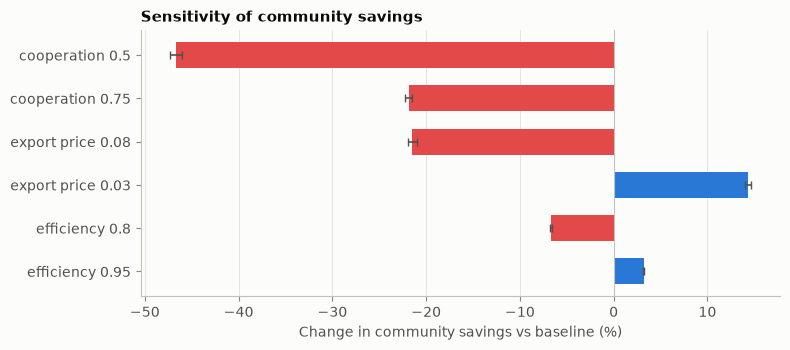

In [20]:
rows = [paired(e5, "community_savings_eur", sc, "baseline") for sc in e5["scenario"].unique() if sc != "baseline"]
sens = pd.DataFrame(rows).set_index("a")
base_mean = e5.loc[e5["scenario"] == "baseline", "community_savings_eur"].mean()
for c in ["mean_diff", "ci_low", "ci_high"]:
    sens[c + "_pct"] = 100 * sens[c] / base_mean
display(sens.round(4))

order = sens["mean_diff_pct"].abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 3.6))
vals = sens.loc[order, "mean_diff_pct"]
err = [vals - sens.loc[order, "ci_low_pct"], sens.loc[order, "ci_high_pct"] - vals]
ax.barh(order, vals, xerr=err, color=[BLUE if v > 0 else RED for v in vals], height=0.6,
        error_kw={"elinewidth": 1.2, "capsize": 3, "ecolor": INK2})
ax.axvline(0, color=AXIS, lw=0.8)
ax.set_axisbelow(True)
ax.grid(axis="x", color=GRID, lw=0.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Change in community savings vs baseline (%)")
ax.set_title("Sensitivity of community savings", loc="left")
fig.tight_layout()
fig.savefig(FIGS / "e5_sensitivity.png", dpi=150)

**Findings (E5)**

- **Cooperation is the most influential parameter**: if each prosumer offers
  its surplus only half of the time, savings fall by almost half.
- A **lower export price raises the value of sharing** (about +14% at
  0.03 EUR/kWh, −21% at 0.08): local trading is worth the gap between import
  and export prices, so the final tariff choice matters for the euro results.
- Battery efficiency matters little within 80–95% (about −7% to +3%).